# 02-2. 변수 생성과 구간 분할

02(전처리 및 변수 생성)의 3~5장. 02-1에서 정리한 10분 자료로 결빙 영향요인 후보 변수와 노선 구간을 만든다.

02 구성: 02-1 정제·10분 시간축(1~2장) · **02-2 변수 생성·구간 분할·저장(3~5장)** · 02-3 추가 자료 ERA5-Land(6장)

미관측 지점(고속도로 구간)에서도 똑같이 만들 수 있는 변수만 쓴다. 그래서 관측소와 구간에 **같은 함수**로 변수를 만든다.

| 변수 그룹 | 출처 | 만드는 방법 | 이론 근거 (01-1의 0장, 01-6·01-7의 13장) |
|-----------|------|-------------|------------------------------|
| 기상 | AWS 34개소(10분), ASOS 10개소(1시간) | 역거리가중(IDW) 공간 보간, 기온은 고도 보정 | 노면 에너지 수지의 기상 입력(기온·이슬점·풍속·운량·강수, Chapman et al. 2001), 결빙의 수분 공급(강수·적설·응결, Zerr 1997) |
| 주변 도로기상 | RWIS 학습 지점 14개소 | 가까운 RWIS의 노면온도·노면상태 IDW (자기 자신과 검증 지점 제외) | 노면온도의 공간 상관(01-3의 4-7). 열지도 대신 주변 관측으로 공간 투영 |
| 시간 | 관측시각 | 시각, 태양고도, 시즌 경과일 | 일사 가열과 야간 복사냉각의 일변화 |
| 지형 | DEM(30m), 하천 경계 | 표고, 지형 상대고도(TPI), 기복량, 하천 거리, 지형 그늘 | 기온감률, 골짜기 냉기호, 차폐(screening), 하천 주변 습기 (Chapman et al. 2001; Hong et al. 2022) |
| 도로 | 국토부 교량·터널 경계, 중심선 | 교량·터널까지 거리 | 교량 노면 1~2°C 낮음, 터널 입·출구 노면온도 급변 (Hong et al. 2022; 김유정 외 2023) |

하늘시계(SVF)는 선행연구에서 가장 큰 영향 요인이지만, 30m DEM으로 계산한 관측소 SVF는 0.94~1.00으로 차이가 작고 노면온도와 관계가 없어
(01-7의 13-6) 변수로 쓰지 않고 지형 그늘로 대신한다.

- 입력: 02-1의 10분 자료·관측소 정보 (`data/processed/`), 제공 자료 4~8번
- 출력: 지점·구간 변수와 구간 정보 (`data/processed/`, 03~05에서 사용)

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parents[1]  # notebooks/<단계 폴더>/ 에서 실행
sys.path.insert(0, str(ROOT))

from src import config

In [2]:
import json
import warnings

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyogrio
import rasterio
import shapely
from cycler import cycler
from matplotlib import font_manager
from scipy.spatial.distance import cdist
from shapely.ops import substring

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

for font in ["NanumGothic", "Malgun Gothic", "AppleGothic"]:
    if any(f.name == font for f in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = font
        break
plt.rcParams.update({
    "axes.unicode_minus": False,
    "axes.prop_cycle": cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                                     "#e87ba4", "#008300", "#4a3aa7", "#e34948"]),
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "figure.dpi": 100, "lines.linewidth": 1.5,
})

config.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
CRS = 5179  # 중심선·DEM·국토부 경계와 같은 UTM-K

In [3]:
# 02-1에서 저장한 10분 자료와 관측소 정보
rwis = pd.read_parquet(config.PROCESSED_DIR / "rwis_10min.parquet")
stations = pd.read_parquet(config.PROCESSED_DIR / "rwis_stations.parquet")
aws_st = pd.read_parquet(config.PROCESSED_DIR / "aws_stations.parquet")
asos_st = pd.read_parquet(config.PROCESSED_DIR / "asos_stations.parquet")
aws_10min = pd.read_parquet(config.PROCESSED_DIR / "aws_10min.parquet")
asos_10min = pd.read_parquet(config.PROCESSED_DIR / "asos_10min.parquet")

# 10분 시간축 (02-1의 2장과 같음)
TIMES = pd.DatetimeIndex(np.concatenate([
    pd.date_range(start, pd.Timestamp(end) + pd.Timedelta("23:50:00"), freq=config.TIME_STEP)
    for start, end in config.PERIODS
]))
PERIOD_ID = np.concatenate([np.full(len(pd.date_range(s, pd.Timestamp(e) + pd.Timedelta("23:50:00"),
                                                      freq=config.TIME_STEP)), i)
                            for i, (s, e) in enumerate(config.PERIODS)])
PERIOD_SLICES = [np.flatnonzero(PERIOD_ID == i) for i in range(len(config.PERIODS))]


def to_wide(df, col, stns):
    """긴 형식(stn, time, 값)을 (지점 x 시각) 배열로 바꾼다. 없는 시각은 NaN."""
    wide = df.pivot(index="time", columns="stn", values=col).reindex(index=TIMES, columns=stns)
    return wide.to_numpy(dtype="float32").T


def per_period(frame, func):
    """시각 x 지점 DataFrame에 func를 기간별로 적용해 다시 붙인다."""
    return pd.concat([func(frame.iloc[idx]) for idx in PERIOD_SLICES])


AWS_STNS = aws_st["stn"].tolist()
ASOS_STNS = asos_st["stn"].tolist()
AWS = {v: to_wide(aws_10min, v, AWS_STNS) for v in aws_10min.columns.drop(["stn", "time"])}
ASOS = {v: to_wide(asos_10min, v, ASOS_STNS) for v in asos_10min.columns.drop(["stn", "time"])}
print("RWIS:", rwis.shape, "/ AWS 배열:", AWS["ta"].shape, "/ ASOS 배열:", ASOS["cloud"].shape)

RWIS: (587520, 10) / AWS 배열: (34, 34560) / ASOS 배열: (10, 34560)


## 3. 기상·도로·지형 변수

### 3-1. 지형·도로 변수 (정적)

- **표고**: DEM 값. 관측소 제공 고도는 미관측 구간에 없으므로 DEM으로 통일한다.
  DEM은 0~0.89로 정규화되어 있어(01-2의 2-2 참고), 관측소 제공 고도와 비교해 구한 계수를 곱해 미터로 바꾼다.
- **TPI(지형 상대고도)**: 표고 - 반경 1km 평균 표고. 음수면 골짜기로, 찬 공기가 고이기 쉽다.
- **기복량**: 반경 1km 최고-최저 표고. 산지일수록 크다.
- **하천 거리**: 국토부 하천 경계(polygon)까지 거리. 하천 주변은 습도가 높고 안개가 잦다.
- **교량·터널 거리**: 국토부 교량·터널 경계 중 고속도로 중심선과 겹치는 것(고속도로 교량·터널)까지 거리.

In [4]:
def to_points(df, lon="lon", lat="lat"):
    return gpd.GeoDataFrame(df.copy(), geometry=gpd.points_from_xy(df[lon], df[lat]), crs=4326).to_crs(CRS)


stations = to_points(stations)
aws_st = to_points(aws_st)
asos_st = to_points(asos_st)
xy = lambda g: np.c_[g.geometry.x, g.geometry.y]

with rasterio.open(config.RAW_DIR / config.RAW_FILES["dem"]) as src:
    DEM = src.read(1).astype("float32")
    DEM_TF = src.transform
    raw_at_stn = np.array([v[0] for v in src.sample(xy(stations))])
DEM[DEM < -1000] = np.nan
DEM_RES = DEM_TF.a

# DEM은 0~0.89로 정규화된 값이다 (01-2의 2-2 참고). RWIS 제공 고도와 원점 회귀로 미터 환산 계수를 구한다.
DEM_SCALE = float((raw_at_stn * stations["alt_given"]).sum() / (raw_at_stn ** 2).sum())
DEM *= DEM_SCALE
print(f"DEM 환산 계수 {DEM_SCALE:.1f} → 표고 범위 {np.nanmin(DEM):.0f} ~ {np.nanmax(DEM):.0f} m")


def terrain_features(xy, radius_m=1000):
    """점별 표고, TPI, 기복량. DEM 밖이면 NaN, 점 위치만 nodata(해안 등)이면 주변 평균 표고를 쓴다."""
    r = int(round(radius_m / DEM_RES))
    yy, xx = np.mgrid[-r:r + 1, -r:r + 1]
    disk = (xx ** 2 + yy ** 2) <= r ** 2
    rows = []
    for x, y in xy:
        col, row = ~DEM_TF * (x, y)
        row, col = int(row), int(col)
        win = DEM[row - r:row + r + 1, col - r:col + r + 1][disk] if (
            r <= row < DEM.shape[0] - r and r <= col < DEM.shape[1] - r) else np.array([np.nan])
        if np.isnan(win).all():
            rows.append((np.nan, np.nan, np.nan))
            continue
        mean = np.nanmean(win)
        elev = DEM[row, col] if not np.isnan(DEM[row, col]) else mean
        rows.append((elev, elev - mean, np.nanmax(win) - np.nanmin(win)))
    return pd.DataFrame(rows, columns=["elev", "tpi", "relief"])


stations[["elev", "tpi", "relief"]] = terrain_features(xy(stations)).to_numpy()
aws_st["elev"] = terrain_features(xy(aws_st), radius_m=30)["elev"].fillna(0).to_numpy()   # DEM 밖 섬 지점은 0m
asos_st["elev"] = terrain_features(xy(asos_st), radius_m=30)["elev"].fillna(0).to_numpy()
stations[["stn", "name", "kind", "alt_given", "elev", "tpi", "relief"]].round(1)

DEM 환산 계수 1955.9 → 표고 범위 0 ~ 1734 m


,stn,name,kind,alt_given,elev,tpi,relief
0,12103,군산휴(도),거점,33,22.200001,-6.500000,136.100006
1,12209,서김제(도),기본,12,20.200001,-0.000000,0.000000
2,12210,부안고려청자휴(도),기본,10,20.200001,-0.000000,15.100000
3,12211,고인돌휴(도),기본,52,60.500000,-35.700001,240.000000
4,12409,우곡3교(도),목표(결빙),13,20.200001,-0.400000,20.200001
5,12410,부곡교(도),목표(결빙),17,20.200001,-0.900000,39.299999
6,23202,여산휴(도),기본,70,61.500000,-15.600000,99.800003
7,23203,삼례졸음(도),기본,25,20.200001,-0.000000,0.000000
8,23204,정읍휴(도),기본,31,20.200001,-3.500000,40.299999
9,23402,해전(도),목표(결빙),13,20.200001,-0.000000,0.000000


In [5]:
centerline = gpd.read_file(config.RAW_DIR / config.RAW_FILES["centerline"])
zip_root = f"/vsizip/{config.RAW_DIR / config.RAW_FILES['boundary']}/국토교통부 도로, 교량, 터널, 하천 경계 데이터"
bbox = tuple(centerline.buffer(5000).total_bounds)  # 고속도로 주변 5km만 읽는다


def read_boundary(path):
    return pyogrio.read_dataframe(f"{zip_root}/{path}", bbox=bbox).to_crs(CRS)


def on_highway(layer, min_ratio):
    """고속도로가 지나가는 교량·터널만 남긴다.

    중심선(10m 버퍼)과 겹치더라도, 중심선이 객체 안을 지나는 길이가 객체 길이(LENG)의 min_ratio 미만이면
    고속도로를 가로지르는 다른 도로의 교량·터널로 보고 뺀다.
    """
    road_buf = gpd.GeoDataFrame(geometry=centerline.buffer(10), crs=CRS)
    hit = layer.loc[gpd.sjoin(layer, road_buf, predicate="intersects").index.unique()].copy()
    inside = hit.intersection(centerline.union_all()).length
    keep = inside >= min_ratio * hit["LENG"].where(hit["LENG"] > 0, 40)
    return hit[keep].reset_index(drop=True)


bridges_poly = read_boundary("N3A_A0070000(교량)_국토부_디지털트윈국토/N3A_A0070000.shp")
tunnels_poly = read_boundary("N3A_A0110020(터널)_국토부_디지털트윈국토/N3A_A0110020.shp")
rivers = read_boundary("국가기본도_하천경계_국토부_디지털트윈국토/TN_RIVER_BNDRY.shp")
hw_bridges = on_highway(bridges_poly, min_ratio=0.5)
hw_tunnels = on_highway(tunnels_poly, min_ratio=0.3)  # 육십령터널은 도 경계에 걸쳐 절반만 들어온다
print(f"고속도로 교량 polygon {len(hw_bridges)}개 (전체 {len(bridges_poly)}개 중)")
print(f"고속도로 터널 polygon {len(hw_tunnels)}개: {sorted(hw_tunnels['NAME'].dropna().unique())}")
print(f"하천 경계 polygon {len(rivers)}개")

고속도로 교량 polygon 219개 (전체 19449개 중)
고속도로 터널 polygon 16개: ['가옥터널', '대명터널', '모두재터널', '오동터널', '육십령터널', '적상터널', '집재터널', '호남터널']
하천 경계 polygon 16011개


In [6]:
# 제공된 교량·터널 위경도(4, 5번). 터널은 경도·위도 순서
bridge_pts = pd.read_csv(config.RAW_DIR / config.RAW_FILES["bridge"], encoding=config.CSV_ENCODING).drop_duplicates()
bridge_pts = to_points(bridge_pts, lon="교량시작점경도", lat="교량시작점위도")
tunnel_pts = pd.read_csv(config.RAW_DIR / config.RAW_FILES["tunnel"], encoding=config.CSV_ENCODING).drop_duplicates()
tunnel_pts = to_points(tunnel_pts, lon="터널시작점경도", lat="터널시작점위도")
print("교량 위치(제공)", len(bridge_pts), "/ 터널 위치(제공)", len(tunnel_pts))


def nearest_distance(points, layer, cap=None):
    _, dist = layer.sindex.nearest(points.geometry, return_distance=True, return_all=False)
    return np.minimum(dist, cap) if cap else dist


def road_terrain_distances(points):
    return pd.DataFrame({
        "dist_bridge": nearest_distance(points, hw_bridges, cap=5000),
        "dist_tunnel": nearest_distance(points, hw_tunnels, cap=20000),
        "dist_river": nearest_distance(points, rivers, cap=5000),
    }, index=points.index)


stations[["dist_bridge", "dist_tunnel", "dist_river"]] = road_terrain_distances(stations)
stations[["stn", "name", "kind", "dist_bridge", "dist_tunnel", "dist_river"]].round(0)

교량 위치(제공) 151 / 터널 위치(제공) 7


,stn,name,kind,dist_bridge,dist_tunnel,dist_river
0,12103,군산휴(도),거점,397.0,2812.0,450.0
1,12209,서김제(도),기본,30.0,17990.0,436.0
2,12210,부안고려청자휴(도),기본,535.0,20000.0,345.0
3,12211,고인돌휴(도),기본,978.0,11268.0,744.0
4,12409,우곡3교(도),목표(결빙),77.0,1568.0,213.0
5,12410,부곡교(도),목표(결빙),54.0,20000.0,545.0
6,23202,여산휴(도),기본,138.0,20000.0,159.0
7,23203,삼례졸음(도),기본,489.0,20000.0,483.0
8,23204,정읍휴(도),기본,1065.0,15446.0,964.0
9,23402,해전(도),목표(결빙),41.0,20000.0,144.0


이름에 '교'가 붙은 관측소(우곡3교, 부곡교, 삼가2교 등)는 교량까지 거리가 짧고,
호남터널 관측소는 터널 바로 옆이다. 좌표 오차(수십 m)가 있어 0이 아닌 경우도 있다.

### 3-2. 기상 변수 (공간 보간)

임의 지점의 기상값을 주변 관측소의 **역거리가중(IDW, 가까운 4개소, 거리 제곱 반비례)** 평균으로 만든다.

- 기온·지면온도는 표준 기온감률(0.65°C/100m), 이슬점은 0.2°C/100m로 고도를 보정한다.
  (관측소 값을 해수면 기준으로 바꾸어 보간한 뒤 대상 지점 고도로 되돌린다.)
  Chapman et al.(2001)은 대기 안정도에 따라 감률을 0~9°C/km로 바꾸어 쓰지만, 이 지역 AWS(산 정상 제외)의 밤 감률은
  안정도와 관계없이 0.73~0.82°C/100m로 거의 일정해(01-7의 13-5) 고정 감률을 쓴다.
- 관측소별 결측은 그 시각에 남은 관측소로만 가중평균한다.

In [7]:
LAPSE = {"ta": 0.0065, "tg": 0.0065, "td": 0.002}  # °C/m


def idw_weights(tgt_xy, src_xy, k=4, power=2, exclude=None):
    """(대상 x 관측소) IDW 가중치 행렬. exclude[i]=j 이면 대상 i에서 관측소 j를 뺀다 (자기 자신 제외용)."""
    d = cdist(tgt_xy, src_xy)
    if exclude is not None:
        for i, j in enumerate(exclude):
            if j >= 0:
                d[i, j] = np.inf
    w = np.zeros_like(d)
    nearest = np.argsort(d, axis=1)[:, :k]
    rows = np.arange(len(d))[:, None]
    w[rows, nearest] = 1.0 / np.maximum(d[rows, nearest], 50.0) ** power
    return w.astype("float32")


def idw_apply(w, values):
    """values: (관측소 x 시각). 결측 관측소는 그 시각 가중치에서 빠진다."""
    ok = ~np.isnan(values)
    num = w @ np.where(ok, values, 0)
    den = w @ ok.astype("float32")
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.where(den > 0, num / den, np.nan).astype("float32")


def interpolate_field(w, values, var, src_elev, tgt_elev):
    lapse = LAPSE.get(var)
    if lapse is None:
        return idw_apply(w, values)
    sea_level = values + lapse * src_elev[:, None]
    return idw_apply(w, sea_level) - lapse * tgt_elev[:, None]

### 3-3. 주변 도로기상 변수 (RWIS)

미관측 지점이라도 같은 시각 **주변 RWIS 관측소**의 노면온도·노면상태는 알 수 있다.

- 원천 관측소: 검증 지점 3곳을 뺀 **학습 지점 14곳**. 학습 지점 자신의 변수를 만들 때는 자기 자신을 뺀다(leave-one-out).
  이렇게 해야 학습할 때도 미관측 지점과 같은 조건(자기 관측값 없이 주변 값만 사용)이 된다.
- `nbr_rst`: 주변 노면온도 IDW (고도 보정)
- `nbr_anom`: 주변 관측소의 (노면온도 - 그 위치 보간 기온) IDW → `rst_phys` = 대상 지점 보간 기온 + `nbr_anom`
- `nbr_ice`, `nbr_wet`, `nbr_snow`: 주변 관측소의 Ice / 젖음(Wet·Damp·Snow·Ice 등) / Snow 비율 (IDW)

In [8]:
TRAIN_STNS = stations.loc[~stations["holdout"], "stn"].tolist()
src_rwis = stations.set_index("stn").loc[TRAIN_STNS]
WET_STATES = [2, 3, 4, 11, 12, 13, 14, 15]

state_w = to_wide(rwis, "state", TRAIN_STNS)
RWIS_SRC = {
    "rst": to_wide(rwis, "rst", TRAIN_STNS),
    "ice": np.where(np.isnan(state_w), np.nan, np.isin(state_w, config.ICE_STATE_CODES)).astype("float32"),
    "wet": np.where(np.isnan(state_w), np.nan, np.isin(state_w, WET_STATES)).astype("float32"),
    "snow": np.where(np.isnan(state_w), np.nan, state_w == 3).astype("float32"),
}
# 원천 관측소 위치의 보간 기온 (노면온도 - 기온 편차 계산용)
w_src = idw_weights(xy(src_rwis), xy(aws_st))
RWIS_SRC["ta"] = interpolate_field(w_src, AWS["ta"], "ta", aws_st["elev"].to_numpy(), src_rwis["elev"].to_numpy())
RWIS_SRC["anom"] = RWIS_SRC["rst"] - RWIS_SRC["ta"]
print("학습 지점(원천) 14곳:", TRAIN_STNS)

학습 지점(원천) 14곳: [12103, 12209, 12210, 12211, 12409, 23202, 23203, 23204, 23403, 33103, 33206, 33409, 33410, 33412]


### 3-4. 시간·일사 변수와 이동 통계

- 태양고도·방위각: 낮 동안 노면 가열, 밤 동안 복사냉각을 나타낸다 (NOAA 근사식).
- **지형 그늘**: DEM으로 지점마다 방위별(10도 간격, 반경 5km) 지형 수평선 고도각을 구하고,
  태양이 그보다 낮으면 산에 가려 그늘(`sunlit`=0)로 본다. 겨울 해는 낮게 떠서 산지 도로는 낮에도 그늘진 시간이 길다.
  - `solar_eff` = 보간 일조 x sin(태양고도) x 햇빛 노출 → 노면에 실제로 닿는 직달 일사의 근사
  - `shade_winter`(정적): 동지 무렵 하루 직달 일사 중 지형에 가려지는 비율 (태양고도 가중) → 05-2의 지형 위험 요인으로도 쓴다
- 이동 통계: 1·3시간 기온 변화, 12시간 최저기온, 3시간 평균 습도, 최근 12시간 강수 시간, 마지막 강수 후 경과시간.
  노면이 젖은 뒤 기온이 떨어지면 결빙이 잘 생긴다.

In [9]:
def sun_position(times, lat, lon):
    """태양고도·방위각(도, 북=0 시계방향). times: DatetimeIndex(KST), lat/lon: 지점별 배열 → (지점 x 시각)."""
    doy = times.dayofyear.to_numpy()
    hour = (times.hour + times.minute / 60).to_numpy()
    g = 2 * np.pi / 365 * (doy - 1 + (hour - 12) / 24)
    decl = (0.006918 - 0.399912 * np.cos(g) + 0.070257 * np.sin(g) - 0.006758 * np.cos(2 * g)
            + 0.000907 * np.sin(2 * g) - 0.002697 * np.cos(3 * g) + 0.00148 * np.sin(3 * g))
    eqtime = 229.18 * (0.000075 + 0.001868 * np.cos(g) - 0.032077 * np.sin(g)
                       - 0.014615 * np.cos(2 * g) - 0.040849 * np.sin(2 * g))
    tst = hour * 60 + eqtime + 4 * np.asarray(lon)[:, None] - 60 * 9
    ha = np.radians(tst / 4 - 180)
    lat = np.radians(np.asarray(lat))[:, None]
    cos_z = np.sin(lat) * np.sin(decl) + np.cos(lat) * np.cos(decl) * np.cos(ha)
    elev = 90 - np.degrees(np.arccos(np.clip(cos_z, -1, 1)))
    azim = (np.degrees(np.arctan2(np.sin(ha), np.cos(ha) * np.sin(lat) - np.tan(decl) * np.cos(lat))) + 180) % 360
    return elev.astype("float32"), azim.astype("float32")


N_AZ = 36  # 지형 수평선 방위 구간 (10도 간격)


def horizon_angles(xy, elev, max_dist=5000, step=60):
    """점별·방위별 지형 수평선 고도각(도). 이보다 태양이 낮으면 산에 가려 그늘이 진다."""
    az = np.radians(np.arange(N_AZ) * 360 / N_AZ)
    dists = np.arange(step, max_dist + step, step)
    out = np.zeros((len(xy), N_AZ), dtype="float32")
    for i, ((x, y), z0) in enumerate(zip(xy, elev)):
        px = x + np.sin(az)[:, None] * dists  # 방위각: 북=0, 동=90
        py = y + np.cos(az)[:, None] * dists
        col, row = ~DEM_TF * (px, py)
        row, col = row.astype(int), col.astype(int)
        inside = (row >= 0) & (row < DEM.shape[0]) & (col >= 0) & (col < DEM.shape[1])
        z = np.full(px.shape, np.nan, dtype="float32")
        z[inside] = DEM[row[inside], col[inside]]
        with np.errstate(invalid="ignore"):
            ang = np.degrees(np.arctan((z - z0) / dists))
        out[i] = np.clip(np.nan_to_num(ang, nan=0).max(axis=1), 0, None)
    return out


def terrain_shading(times, lat, lon, horizon):
    """(지점 x 시각) 햇빛 노출 여부: 태양이 떠 있고 지형 수평선보다 높으면 1."""
    sun_elev, sun_az = sun_position(times, lat, lon)
    az_bin = np.round(sun_az / (360 / N_AZ)).astype(int) % N_AZ
    hz = np.take_along_axis(horizon, az_bin, axis=1)
    return sun_elev, (sun_elev > np.maximum(hz, 0)).astype("float32")


def winter_shade_ratio(points, horizon, day="2024-12-22"):
    """동지 무렵 하루 동안 지형에 가려지는 직달 일사 비율 (정적 변수).

    해가 낮은 일출·일몰 무렵보다 한낮의 그늘이 노면 온도에 더 중요하므로 sin(태양고도)로 가중한다.
    """
    t = pd.date_range(day, periods=144, freq="10min")
    sun_elev, sunlit = terrain_shading(t, points["lat"].to_numpy(), points["lon"].to_numpy(), horizon)
    energy = np.sin(np.radians(np.clip(sun_elev, 0, None)))
    return 1 - (energy * sunlit).sum(axis=1) / energy.sum(axis=1)


def rolling_features(ta, rh, rain):
    """(지점 x 시각) 배열로 이동 통계를 만든다. 기간별로 따로 계산."""
    f = lambda a: pd.DataFrame(a.T)
    out = {
        "ta_d1h": per_period(f(ta), lambda d: d.diff(6)),
        "ta_d3h": per_period(f(ta), lambda d: d.diff(18)),
        "ta_min12h": per_period(f(ta), lambda d: d.rolling(72, min_periods=36).min()),
        "rh_mean3h": per_period(f(rh), lambda d: d.rolling(18, min_periods=9).mean()),
        "rain_hrs12h": per_period(f(rain), lambda d: d.rolling(72, min_periods=36).sum() / 6),
    }

    def hours_since(d, cap=72.0):
        step = np.arange(len(d), dtype="float32")[:, None]
        last = pd.DataFrame(np.where(d.to_numpy() >= 0.5, step, np.nan)).ffill().to_numpy()
        return pd.DataFrame(np.minimum((step - last) / 6, cap)).fillna(cap)

    out["hrs_since_rain"] = per_period(f(rain), hours_since)
    return {k: v.to_numpy(dtype="float32").T for k, v in out.items()}

In [10]:
stations["shade_winter"] = winter_shade_ratio(stations, horizon_angles(xy(stations), stations["elev"].to_numpy()))
stations[["stn", "name", "route", "elev", "shade_winter"]].round(2)

,stn,name,route,elev,shade_winter
0,12103,군산휴(도),서해안,22.180000,0.18
1,12209,서김제(도),서해안,20.160000,0.00
2,12210,부안고려청자휴(도),서해안,20.160000,0.00
3,12211,고인돌휴(도),서해안,60.490002,0.03
4,12409,우곡3교(도),서해안,20.160000,0.01
5,12410,부곡교(도),서해안,20.160000,0.00
6,23202,여산휴(도),호남선,61.500000,0.02
7,23203,삼례졸음(도),호남선,20.160000,0.00
8,23204,정읍휴(도),호남선,20.160000,0.01
9,23402,해전(도),호남선,20.160000,0.00


통영-대전중부선 산지 관측소는 동지 무렵 직달 일사의 상당 부분이 지형에 가려지고, 평지인 서해안선은 거의 가려지지 않는다.

### 3-5. 지점 변수 만들기

위 단계를 묶어, 좌표·표고 등 정적 변수가 있는 지점 목록을 넣으면 (지점, 시각)별 변수 표를 돌려주는 함수를 만든다.
관측소(17곳)와 구간(4장)에 모두 이 함수를 쓴다.

In [11]:
STATIC_FEATURES = ["elev", "tpi", "relief", "shade_winter", "dist_river", "dist_bridge", "dist_tunnel"]
FEATURE_GROUPS = {
    "기상": ["ta", "td", "rh", "dpd", "ws", "rain", "pr60", "pr12h", "pr_day", "cloud", "tg", "snow", "sunshine",
           "ta_d1h", "ta_d3h", "ta_min12h", "rh_mean3h", "rain_hrs12h", "hrs_since_rain"],
    "주변도로기상": ["nbr_rst", "nbr_anom", "rst_phys", "nbr_ice", "nbr_ice_3h", "nbr_wet", "nbr_snow", "nbr_dist"],
    "시간·일사": ["hour_sin", "hour_cos", "sun_elev", "season_day", "sunlit", "solar_eff"],
    "지형": ["elev", "tpi", "relief", "shade_winter", "dist_river"],
    "도로": ["dist_bridge", "dist_tunnel"],
}
FEATURES = [f for g in FEATURE_GROUPS.values() for f in g]


def build_point_features(points, id_col, exclude_self=False, every=1):
    """points: 좌표·정적 변수가 있는 GeoDataFrame → (id, time)별 변수 DataFrame.

    exclude_self: 학습 지점 자신을 주변 RWIS 원천에서 뺀다 (관측소용).
    every: 시각 간격 (1=10분, 6=1시간). 이동 통계는 10분 자료로 계산한 뒤 고른다.
    """
    p_xy, p_elev = xy(points), points["elev"].to_numpy()
    feats = {}

    w = idw_weights(p_xy, xy(aws_st))
    for var in AWS:
        feats[var] = interpolate_field(w, AWS[var], var, aws_st["elev"].to_numpy(), p_elev)
    w = idw_weights(p_xy, xy(asos_st), k=3)
    for var in ASOS:
        feats[var] = interpolate_field(w, ASOS[var], var, asos_st["elev"].to_numpy(), p_elev)
    feats["dpd"] = feats["ta"] - feats["td"]
    feats.update(rolling_features(feats["ta"], feats["rh"], feats["rain"]))

    exclude = None
    if exclude_self:
        pos = {s: i for i, s in enumerate(TRAIN_STNS)}
        exclude = [pos.get(s, -1) for s in points[id_col]]
    w = idw_weights(p_xy, xy(src_rwis), k=3, exclude=exclude)
    feats["nbr_rst"] = interpolate_field(w, RWIS_SRC["rst"], "ta", src_rwis["elev"].to_numpy(), p_elev)
    feats["nbr_anom"] = idw_apply(w, RWIS_SRC["anom"])
    feats["rst_phys"] = feats["ta"] + feats["nbr_anom"]
    for var in ["ice", "wet", "snow"]:
        feats[f"nbr_{var}"] = idw_apply(w, RWIS_SRC[var])
    feats["nbr_ice_3h"] = per_period(pd.DataFrame(feats["nbr_ice"].T),
                                     lambda d: d.rolling(18, min_periods=1).max()).to_numpy("float32").T
    d = cdist(p_xy, xy(src_rwis))
    if exclude is not None:
        for i, j in enumerate(exclude):
            if j >= 0:
                d[i, j] = np.inf
    nbr_dist = d.min(axis=1) / 1000

    horizon = horizon_angles(p_xy, p_elev)
    feats["sun_elev"], feats["sunlit"] = terrain_shading(TIMES, points["lat"].to_numpy(),
                                                         points["lon"].to_numpy(), horizon)
    feats["solar_eff"] = feats["sunshine"] * np.sin(np.radians(np.clip(feats["sun_elev"], 0, None))) * feats["sunlit"]

    t_sel = np.arange(0, len(TIMES), every)
    n_p, n_t = len(points), len(t_sel)
    out = pd.DataFrame({
        id_col: np.repeat(points[id_col].to_numpy(), n_t),
        "time": np.tile(TIMES[t_sel], n_p),
    })
    for k, v in feats.items():
        out[k] = v[:, t_sel].ravel()
    hour = out["time"].dt.hour + out["time"].dt.minute / 60
    out["hour_sin"] = np.sin(2 * np.pi * hour / 24).astype("float32")
    out["hour_cos"] = np.cos(2 * np.pi * hour / 24).astype("float32")
    season_start = pd.to_datetime(out["time"].dt.year.where(out["time"].dt.month >= 11, out["time"].dt.year - 1)
                                  .astype(str) + "-11-01")
    out["season_day"] = ((out["time"] - season_start).dt.days).astype("int16")
    out["nbr_dist"] = np.repeat(nbr_dist, n_t).astype("float32")
    for c in STATIC_FEATURES:
        out[c] = np.repeat(points[c].to_numpy(), n_t).astype("float32")
    return out[[id_col, "time", *FEATURES]]

In [12]:
st_feat = build_point_features(stations, "stn", exclude_self=True)
station_features = st_feat.merge(rwis[["stn", "time", "state", "ice", "rst", "ta", "rh"]]
                                 .rename(columns={"ta": "ta_obs", "rh": "rh_obs"}), on=["stn", "time"])
print(station_features.shape)
station_features[FEATURES].describe().T.round(2)

(587520, 47)


,count,mean,std,min,25%,50%,75%,max
ta,587520.0,2.22,6.40,-18.24,-2.25,1.62,6.33,23.52
td,587520.0,-3.39,6.64,-24.03,-8.11,-3.44,0.91,16.36
rh,587520.0,70.93,17.96,10.23,58.30,73.47,85.71,99.74
dpd,587520.0,5.61,4.15,-0.49,2.43,4.62,7.86,31.54
ws,587520.0,1.96,1.34,0.00,0.94,1.71,2.72,12.72
rain,587520.0,0.05,0.17,0.00,0.00,0.00,0.00,1.00
pr60,587520.0,0.03,0.18,0.00,0.00,0.00,0.00,6.10
pr12h,587520.0,0.36,1.39,0.00,0.00,0.00,0.00,23.97
pr_day,587520.0,0.39,1.51,0.00,0.00,0.00,0.00,22.83
cloud,587520.0,4.65,3.89,0.00,0.04,4.93,8.64,10.00


보간한 기온과 RWIS 관측소가 직접 잰 기온(기본·거점 관측소)을 비교해 보간이 적절한지 확인한다.

In [13]:
chk = station_features.dropna(subset=["ta_obs", "ta"])
err = (chk["ta"] - chk["ta_obs"]).groupby(chk["stn"]).agg(BIAS="mean", MAE=lambda e: e.abs().mean())
err["보간_습도_MAE"] = (chk["rh"] - chk["rh_obs"]).abs().groupby(chk["stn"]).mean()
err.join(stations.set_index("stn")[["name", "kind"]]).round(2)

,BIAS,MAE,보간_습도_MAE,name,kind
stn,,,,,
12103,-0.24,0.67,4.79,군산휴(도),거점
12209,0.37,0.64,3.48,서김제(도),기본
12210,-0.10,0.50,7.72,부안고려청자휴(도),기본
12211,-0.04,0.81,7.92,고인돌휴(도),기본
23202,-1.30,1.38,7.29,여산휴(도),기본
23203,-0.21,0.95,4.40,삼례졸음(도),기본
23204,-0.68,0.93,4.06,정읍휴(도),기본
33103,-0.79,0.97,7.56,덕유산휴(도),거점
33206,-0.70,1.20,4.68,용포1교(도),기본


보간 기온의 오차는 대부분 1~2°C 이내이다. 노면온도는 기온 외에도 일사·복사냉각·노면 구조의 영향을 받으므로,
보간 기온과 주변 RWIS 정보를 함께 입력해 03에서 모델로 추정한다.

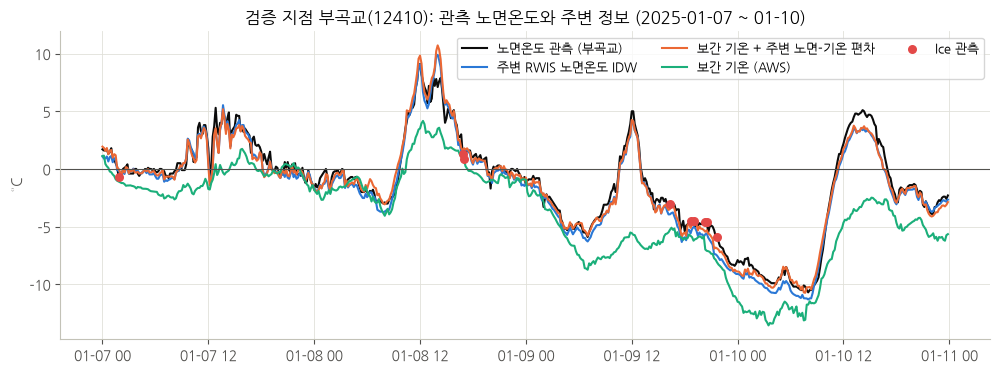

In [14]:
check = station_features[station_features["stn"] == 12410].set_index("time").loc["2025-01-07":"2025-01-10"]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(check.index, check["rst"], label="노면온도 관측 (부곡교)", color="#0b0b0b")
ax.plot(check.index, check["nbr_rst"], label="주변 RWIS 노면온도 IDW", color="#2a78d6")
ax.plot(check.index, check["rst_phys"], label="보간 기온 + 주변 노면-기온 편차", color="#eb6834")
ax.plot(check.index, check["ta"], label="보간 기온 (AWS)", color="#1baf7a")
ice_t = check.index[check["ice"] == 1]
ax.scatter(ice_t, check.loc[ice_t, "rst"], color="#e34948", s=30, zorder=5, label="Ice 관측")
ax.axhline(0, color="#52514e", linewidth=0.8)
ax.set_ylabel("°C")
ax.set_title("검증 지점 부곡교(12410): 관측 노면온도와 주변 정보 (2025-01-07 ~ 01-10)")
ax.legend(ncol=3, fontsize=9)
plt.show()

## 4. 노선 구간 분할
대상 3개 노선, config.SEGMENT_LENGTH_M 단위

1. 중심선에서 **본선**만 고른다: 양방통행(ITH002)이거나 2차로 이상인 선형. 1차로 일방통행은 IC·JC 연결로로 본다.
2. 노선별로 선형을 이어 붙이고(line merge), 300m 미만 조각은 버린다.
3. 각 선형을 `SEGMENT_LENGTH_M`에 가장 가까운 같은 길이로 나눈다.
4. 상·하행이 분리된 곳은 같은 위치에 구간이 두 개 생기므로, 중간점이 이미 만든 구간과 100m 이내이면 뺀다.

In [15]:
ROUTE_NAMES = {"서해안고속국도": "서해안", "통영-대전고속국도": "통영-대전중부선", "호남고속국도": "호남선"}
ROUTE_CODES = {"서해안": "SH", "통영-대전중부선": "TD", "호남선": "HN"}


def split_route_segments(centerline, length_m=config.SEGMENT_LENGTH_M, min_part_m=300, dedup_m=100):
    main = centerline[(centerline["ONSD"] == "ITH002") | (centerline["RDLN"] >= 2)]
    rows = []
    for name, g in main.groupby("NAME"):
        route = ROUTE_NAMES[name]
        merged = shapely.line_merge(shapely.union_all(g.geometry.to_numpy()))
        parts = sorted(getattr(merged, "geoms", [merged]), key=lambda p: p.length, reverse=True)
        kept_mid = []
        for part in parts:
            if part.length < min_part_m:
                continue
            n = max(1, round(part.length / length_m))
            step = part.length / n
            for i in range(n):
                seg = substring(part, i * step, (i + 1) * step)
                mid = seg.interpolate(0.5, normalized=True)
                if kept_mid and min(mid.distance(m) for m in kept_mid) < dedup_m:
                    continue
                kept_mid.append(mid)
                rows.append({"route": route, "geometry": seg})
    seg = gpd.GeoDataFrame(rows, crs=centerline.crs)
    mid = seg.geometry.interpolate(0.5, normalized=True)
    seg["mid_x"], seg["mid_y"] = mid.x, mid.y
    # 노선별로 남→북 순서 번호
    seg = seg.sort_values(["route", "mid_y"]).reset_index(drop=True)
    seg["seg_id"] = seg["route"].map(ROUTE_CODES) + "-" + (seg.groupby("route").cumcount() + 1).astype(str).str.zfill(3)
    seg["length_m"] = seg.length.round(1)
    ll = gpd.GeoSeries(gpd.points_from_xy(seg["mid_x"], seg["mid_y"]), crs=CRS).to_crs(4326)
    seg["lon"], seg["lat"] = ll.x, ll.y
    return seg[["seg_id", "route", "length_m", "mid_x", "mid_y", "lon", "lat", "geometry"]]


segments = split_route_segments(centerline)
print(f"구간 {len(segments)}개, 길이 {segments['length_m'].min():.0f}~{segments['length_m'].max():.0f}m")
segments.groupby("route")["length_m"].agg(["count", "sum", "mean"]).round(0)

구간 233개, 길이 318~1238m


,count,sum,mean
route,,,
서해안,100,96860.0,969.0
통영-대전중부선,47,46021.0,979.0
호남선,86,82560.0,960.0


구간별 정적 변수

- 모델 입력(관측소와 같은 정의): 구간 **중간점**의 표고·TPI·기복량·하천/교량/터널 거리
- 위험도 산출용(구간 전체): 교량 비율, 제공 교량 위치 수, 터널 비율과 터널까지 거리, 구간 내 최고 표고

In [16]:
seg_mid = gpd.GeoDataFrame(segments[["seg_id", "lon", "lat"]].copy(),
                           geometry=gpd.points_from_xy(segments["mid_x"], segments["mid_y"]), crs=CRS)
seg_mid[["elev", "tpi", "relief"]] = terrain_features(xy(seg_mid)).to_numpy()
seg_mid[["dist_bridge", "dist_tunnel", "dist_river"]] = road_terrain_distances(seg_mid).to_numpy()
seg_mid["shade_winter"] = winter_shade_ratio(seg_mid, horizon_angles(xy(seg_mid), seg_mid["elev"].to_numpy()))
segments = segments.merge(pd.DataFrame(seg_mid.drop(columns=["geometry", "lon", "lat"])), on="seg_id")

bridge_union = hw_bridges.buffer(5).union_all()
tunnel_union = hw_tunnels.union_all()
segments["bridge_ratio"] = (segments.intersection(bridge_union).length / segments.length).round(3)
segments["tunnel_ratio"] = (segments.intersection(tunnel_union).length / segments.length).round(3)
segments["n_bridge"] = segments.buffer(100).apply(lambda g: int(bridge_pts.intersects(g).sum()))
segments["seg_dist_tunnel"] = segments.distance(tunnel_union).round(0)


def max_elev_along(line, step=100):
    pts = [line.interpolate(d) for d in np.arange(0, line.length + 1, step)]
    return terrain_features([(p.x, p.y) for p in pts], radius_m=30)["elev"].max()


segments["elev_max"] = segments.geometry.apply(max_elev_along)
print("세그먼트 정적 변수 결측:", segments[STATIC_FEATURES].isna().sum().to_dict())
segments.drop(columns="geometry").describe().T.round(2)

세그먼트 정적 변수 결측: {'elev': 0, 'tpi': 0, 'relief': 0, 'shade_winter': 0, 'dist_river': 0, 'dist_bridge': 0, 'dist_tunnel': 0}


,count,mean,std,min,25%,50%,75%,max
length_m,233.0,967.56,135.43,317.70,964.80,994.10,1019.70,1237.90
mid_x,233.0,955375.73,31040.78,915092.52,935799.01,940817.81,964250.06,1014937.39
mid_y,233.0,1750715.94,21347.79,1702471.06,1734199.39,1753161.54,1769451.74,1786129.68
lon,233.0,127.01,0.34,126.57,126.79,126.84,127.10,127.67
lat,233.0,35.75,0.19,35.31,35.60,35.77,35.92,36.07
elev,233.0,100.97,153.85,9.07,20.16,25.21,60.49,776.33
tpi,233.0,-8.17,18.31,-70.34,-12.82,-1.23,-0.00,79.34
relief,233.0,94.10,106.83,0.00,20.16,40.33,152.24,508.14
dist_bridge,233.0,522.37,670.68,0.00,92.33,273.36,709.70,3918.04
dist_tunnel,233.0,12784.10,7643.75,0.00,4685.36,15336.00,20000.00,20000.00


In [17]:
def match_stations_to_segments(segments, stations):
    """관측소를 가장 가까운 구간에 연결한다."""
    idx, dist = segments.sindex.nearest(stations.geometry, return_distance=True, return_all=False)
    out = stations[["stn", "name", "route", "holdout"]].copy()
    out["seg_id"] = segments["seg_id"].to_numpy()[idx[1]]
    out["seg_route"] = segments["route"].to_numpy()[idx[1]]
    out["dist_m"] = dist.round(1)
    return out


station_seg = match_stations_to_segments(segments, stations)
station_seg

,stn,name,route,holdout,seg_id,seg_route,dist_m
0,12103,군산휴(도),서해안,False,SH-099,서해안,20.8
1,12209,서김제(도),서해안,False,SH-070,서해안,36.6
2,12210,부안고려청자휴(도),서해안,False,SH-048,서해안,14.7
3,12211,고인돌휴(도),서해안,False,SH-021,서해안,18.6
4,12409,우곡3교(도),서해안,False,SH-091,서해안,18.6
5,12410,부곡교(도),서해안,True,SH-044,서해안,14.4
6,23202,여산휴(도),호남선,False,HN-083,호남선,20.6
7,23203,삼례졸음(도),호남선,False,HN-067,호남선,11.9
8,23204,정읍휴(도),호남선,False,HN-020,호남선,15.9
9,23402,해전(도),호남선,True,HN-064,호남선,15.7


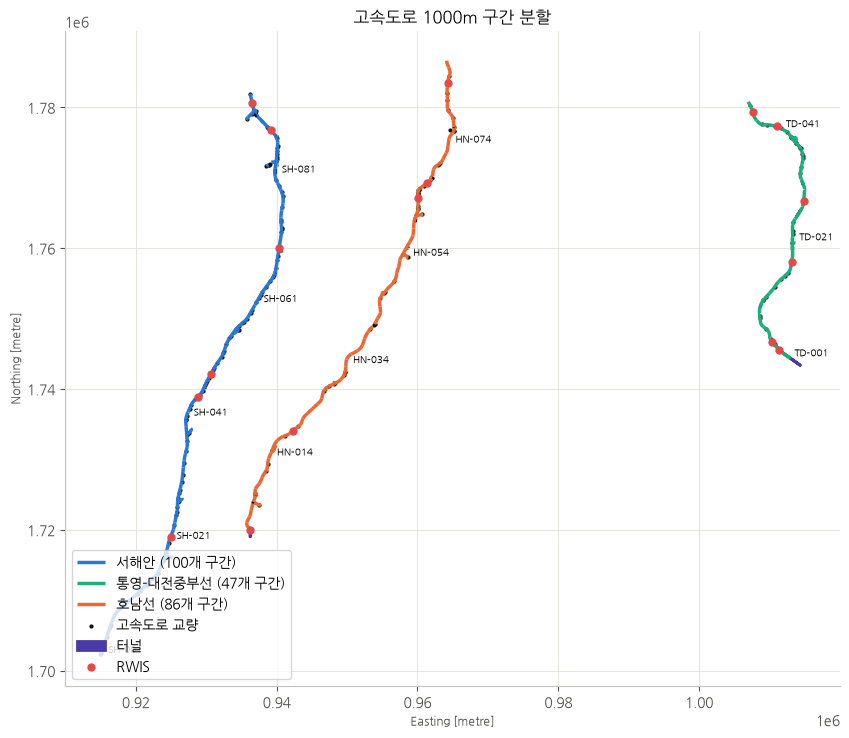

In [18]:
fig, ax = plt.subplots(figsize=(10, 10))
colors = {"서해안": "#2a78d6", "호남선": "#eb6834", "통영-대전중부선": "#1baf7a"}
for route, g in segments.groupby("route"):
    g.plot(ax=ax, color=colors[route], linewidth=2.5, label=f"{route} ({len(g)}개 구간)")
hw_bridges.representative_point().plot(ax=ax, color="#0b0b0b", markersize=4, label="고속도로 교량")
hw_tunnels.plot(ax=ax, color="#4a3aa7", edgecolor="#4a3aa7", linewidth=2, label="터널")
stations.plot(ax=ax, color="#e34948", markersize=25, zorder=5, label="RWIS")
for _, r in segments.iloc[::20].iterrows():
    ax.annotate(r["seg_id"], (r["mid_x"], r["mid_y"]), xytext=(5, 0), textcoords="offset points", fontsize=7)
ax.set_title(f"고속도로 {config.SEGMENT_LENGTH_M}m 구간 분할")
ax.legend(loc="lower left")
ax.set_aspect("equal")
plt.show()

구간 중간점에서 관측소와 같은 방법으로 시계열 변수를 만든다.
구간 수 x 34,560 시각은 매우 크므로 **1시간 간격(정시)**만 저장한다. 이동 통계는 10분 자료로 계산한 뒤 고른다.

In [19]:
seg_points = gpd.GeoDataFrame(segments.drop(columns="geometry"),
                              geometry=gpd.points_from_xy(segments["mid_x"], segments["mid_y"]), crs=CRS)
chunks = []
for start in range(0, len(seg_points), 40):
    chunks.append(build_point_features(seg_points.iloc[start:start + 40], "seg_id", every=6))
segment_features = pd.concat(chunks, ignore_index=True)
del chunks
print(segment_features.shape, f"{segment_features.memory_usage(deep=True).sum() / 1e6:.0f} MB")

(1342080, 42) 242 MB


## 5. 저장
config.PROCESSED_DIR

In [20]:
out = config.PROCESSED_DIR
pd.DataFrame(stations.drop(columns="geometry")).to_parquet(out / "stations.parquet", index=False)
station_features.to_parquet(out / "station_features.parquet", index=False)
station_seg.to_csv(out / "station_segment_match.csv", index=False, encoding="utf-8-sig")
segments.to_file(out / "segments.gpkg", driver="GPKG")
segment_features.to_parquet(out / "segment_features.parquet", index=False)
with open(out / "features.json", "w", encoding="utf-8") as f:
    json.dump({"features": FEATURES, "groups": FEATURE_GROUPS, "static": STATIC_FEATURES, "dem_scale": DEM_SCALE},
              f, ensure_ascii=False, indent=2)

for p in sorted(out.iterdir()):
    print(f"{p.name:32s} {p.stat().st_size / 1e6:8.1f} MB")

asos_10min.parquet                    1.6 MB
asos_stations.parquet                 0.0 MB
aws_10min.parquet                     8.2 MB
aws_stations.parquet                  0.0 MB
features.json                         0.0 MB
rwis_10min.parquet                    3.9 MB
rwis_stations.parquet                 0.0 MB
segment_features.parquet            102.9 MB
segments.gpkg                         0.3 MB
station_estimates.parquet             4.3 MB
station_features.parquet             46.8 MB
station_segment_match.csv             0.0 MB
stations.parquet                      0.0 MB
